# SpearMace gym — EDA of the last two long runs

Exploratory look at the two most recent long self-play runs under `spearmace-gym/`.
All parsing lives in [`spearmace_data.py`](spearmace_data.py); this notebook only analyses.

Tables used:

| table | grain | source |
|---|---|---|
| `episodes` | one row per episode | `episodes.jsonl` |
| `sides` | one row per episode × side (A/B) | `episodes.jsonl` |
| `decisions` | one row per planner decision | `decisions-*.jsonl` (`type=decision`) |
| `actions` | one row per finished action | `decisions-*.jsonl` (`type=action_end`) |
| `stops` | one row per client per episode | `decisions-*.jsonl` (`type=stop`) |
| `candidates` | one row per candidate action per decision | `decisions-*.jsonl` |

The first load parses ~800 MB of JSON in parallel, then reads cached parquet from `analysis/.cache/`.


## Key findings (runs 20261105-002113 and 20261105-075355)

- **Scale:** 1,042 episodes (542 + 500), about 7.3 game-hours per run, 187k decisions, 253k finished actions.
  Runs are very similar: same expert (beam 8x5), explore 0.1, median episode about 23 s.
- **Endings:** about 70% `killed`, about 15% `died` (≈2/3 of the loser's damage is fall damage), 12–14% hit the 3600-tick timeout.
  All 121 draws are timeouts.
- **Search type:** Rules wins about 45% of decided episodes, Beam and MCTS about 52%. Beam beats Rules 0.60, and MCTS edges Beam 0.53.
  Beam width/depth and MCTS iterations show **no clear trend**. Every CI overlaps 0.5, so more planning budget is not buying wins.
- **No side or pair bias** (A vs B within ±3pp).
- **Action mix:** Rules leans on SpearLunge (38%) and almost never Drifts or Cushions. Beam and MCTS Drift 16–20% and Cushion 4–7%.
- **Expert agreement:** 66% for Beam/MCTS, 42% for Rules. Expert labels cover 91% of decisions, and about 9% are skipped.
- **Action reliability:** MaceStrike FAILS 1/3 of the time (`landed before the hit`). WindChargeJump is interrupted 90% of the time.
  PearlCatch fails 13%, but the simulator is *under*-confident (predicted 0.81, realised 0.88).
- **Simulator accuracy:** spear-lunge and mace-launch impulse predictions are essentially exact (median error ≈0). Pearl teleports land
  a median 0.28 blocks from the planned destination, with a long tail (p99 about 22 blocks).
- **Losers' health collapses in the last 20% of an episode.** Resource curves (pearls, wind charges) for winners and losers barely differ.
- **Run 2 server is slower** (mean mspt 1.6 vs 1.0, with 3 pairs vs 2). Decision rate per tick is unchanged.


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import orjson

import spearmace_data as sd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Validated categorical palette (fixed order, first 3 slots are safe for all-pairs use).
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=SLOTS), "legend.frameon": False,
})

SEARCH_ORDER = ["Rules", "Beam search", "MCTS"]
SEARCH_COLORS = dict(zip(SEARCH_ORDER, SLOTS))

In [2]:
RUNS = sd.latest_runs(2, min_episodes=100)
RUN_NAMES = [r.name for r in RUNS]
RUN_COLORS = dict(zip(RUN_NAMES, SLOTS))
print("runs:", RUN_NAMES)

data = sd.load_runs(RUNS, decisions=True, with_candidates=True)
episodes, sides = data["episodes"], data["sides"]
decisions, actions, stops, candidates = data["decisions"], data["actions"], data["stops"], data["candidates"]
for k, v in data.items():
    print(f"{k:11s} {v.shape[0]:>9,d} rows × {v.shape[1]:>2d} cols  {v.memory_usage(deep=True).sum()/1e6:6.0f} MB")

runs: ['20261105-002113', '20261105-075355']
episodes        1,042 rows × 16 cols       0 MB
sides           2,084 rows × 43 cols       1 MB
decisions     186,723 rows × 65 cols     113 MB
actions       253,213 rows × 17 cols      61 MB
stops           2,088 rows × 11 cols       0 MB
candidates    938,084 rows × 21 cols     220 MB


## 1. Run overview

In [3]:
def run_summary(run):
    e = episodes[episodes.run == run]
    d = decisions[decisions.run == run]
    return pd.Series({
        "pairs": e.pair.nunique(),
        "episodes": len(e),
        "decisions": len(d),
        "actions": (actions.run == run).sum(),
        "game hours (sum of episodes)": e.ticks.sum() / 20 / 3600,
        "median episode s": e.seconds.median(),
        "timeouts %": 100 * (e.reason == "timeout").mean(),
        "draws %": 100 * e.winner.isna().mean(),
        "explore": e.explore.iloc[0],
        "expert": e.expert_label.iloc[0],
        "mean mspt": e.msptMean.mean(),
        "max mspt": e.msptMax.max(),
    })

pd.DataFrame({r: run_summary(r) for r in RUN_NAMES}).round(2)

,20261105-002113,20261105-075355
pairs,2,3
episodes,542,500
decisions,93033,93690
actions,125359,127854
game hours (sum of episodes),7.307556,7.370736
median episode s,22.75,23.925
timeouts %,11.99262,14.2
draws %,10.701107,12.6
explore,0.1,0.1
expert,Beam search 8x5,Beam search 8x5


Episodes per pair, and the matchup mix. Each episode samples a fresh config per side;
`rules` is a fixed heuristic, `beam WxD` is beam search width × depth, `mcts N` is MCTS with N iterations.

In [4]:
display(episodes.groupby(["run", "pair"]).size().unstack("pair"))

matchup = sides[sides.side == "A"].assign(m=lambda x: x.search + " vs " + x.opp_search)
pd.crosstab(matchup.m, matchup.run).sort_values(RUN_NAMES[0], ascending=False)

pair,0,1,2
run,,,
20261105-002113,269.0,273.0,NaN
20261105-075355,176.0,149.0,175.0


run,20261105-002113,20261105-075355
m,,
MCTS vs Beam search,71,57
Rules vs Beam search,64,61
Beam search vs Beam search,61,58
Rules vs MCTS,61,56
Rules vs Rules,61,56
Beam search vs MCTS,60,55
Beam search vs Rules,58,58
MCTS vs MCTS,57,55
MCTS vs Rules,49,44


## 2. Episode outcomes and length

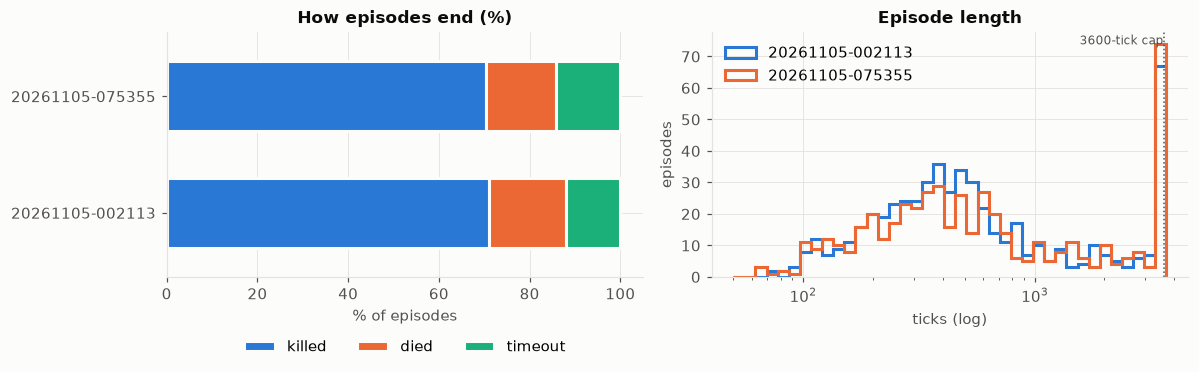

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
reasons = ["killed", "died", "timeout"]
ct = pd.crosstab(episodes.run, episodes.reason, normalize="index")[reasons] * 100
ct.plot.barh(stacked=True, ax=axes[0], color=SLOTS[:3], width=0.6, edgecolor="#fcfcfb", linewidth=2)
axes[0].set(title="How episodes end (%)", xlabel="% of episodes", ylabel="")
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))

bins = np.logspace(np.log10(50), np.log10(3700), 40)
for run in RUN_NAMES:
    axes[1].hist(episodes.loc[episodes.run == run, "ticks"], bins=bins, histtype="step",
                 linewidth=2, color=RUN_COLORS[run], label=run)
axes[1].set_xscale("log")
axes[1].axvline(3600, color=INK2, linestyle=":", linewidth=1)
axes[1].text(3600, axes[1].get_ylim()[1] * 0.95, " 3600-tick cap", color=INK2, fontsize=8, ha="right")
axes[1].set(title="Episode length", xlabel="ticks (log)", ylabel="episodes")
axes[1].legend()
plt.tight_layout()

`killed` = the episode ended because a player died to the opponent; `died` = died with no
credited kill (fall / self-inflicted, typically); `timeout` = hit the tick cap. What kills the
`died` episodes is worth checking against `fall` below.

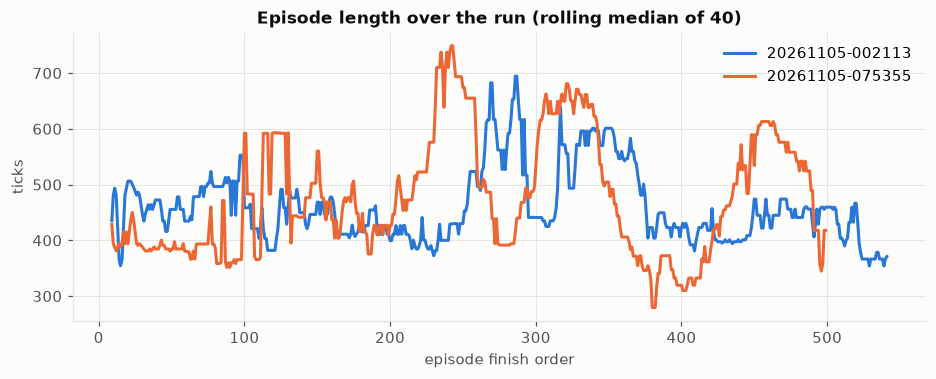

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for run in RUN_NAMES:
    e = episodes[episodes.run == run].sort_values("order")
    ax.plot(e.order, e.ticks.rolling(40, min_periods=10).median(), color=RUN_COLORS[run], label=run)
ax.set(title="Episode length over the run (rolling median of 40)", xlabel="episode finish order", ylabel="ticks")
ax.legend();

In [7]:
# died vs killed: who dies, and how much of their damage taken was fall damage?
loser = sides[(sides.won == False)].copy()
loser["fall_share"] = loser.fall / loser.taken.replace(0, np.nan)
loser.groupby(["run", "reason"])[["taken", "fall", "fall_share", "totemsPopped", "applesEaten"]].median().round(2)

taken   fall  fall_share  totemsPopped  applesEaten
run             reason                                                       
20261105-002113 died     159.69  109.5        0.68           0.0          1.0
                killed   191.02   78.0        0.36           0.0          1.0
                timeout  634.96  278.0        0.44           0.0          7.0
20261105-075355 died     166.12  106.0        0.66           0.0          1.0
                killed   198.61   78.0        0.36           0.0          1.0
                timeout  561.90  248.5        0.45           0.0          6.5

## 3. Who wins? Search type, side and config

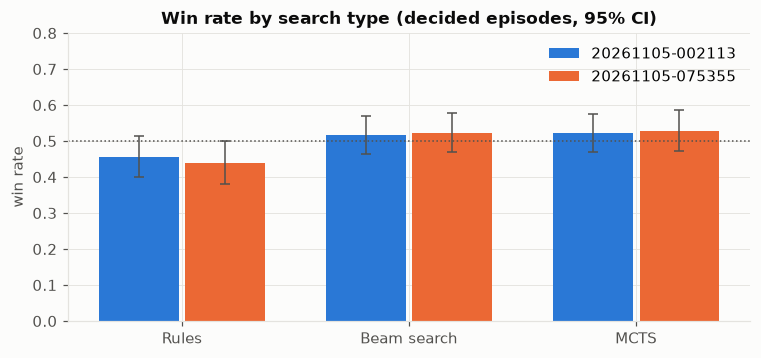

In [8]:
def winrate(df, by):
    g = df[df.won.notna()].groupby(by).won
    out = g.agg(["mean", "size"]).rename(columns={"mean": "win_rate", "size": "n"})
    out["se"] = np.sqrt(out.win_rate * (1 - out.win_rate) / out.n)
    return out

wr = winrate(sides, ["run", "search"]).reset_index()
fig, ax = plt.subplots(figsize=(8, 3.4))
w = 0.38
x = np.arange(len(SEARCH_ORDER))
for i, run in enumerate(RUN_NAMES):
    r = wr[wr.run == run].set_index("search").reindex(SEARCH_ORDER)
    ax.bar(x + (i - 0.5) * w, r.win_rate, w - 0.03, yerr=1.96 * r.se, color=RUN_COLORS[run],
           label=run, error_kw=dict(ecolor=INK2, lw=1, capsize=3))
ax.axhline(0.5, color=INK2, linewidth=1, linestyle=":")
ax.set_xticks(x, SEARCH_ORDER)
ax.set(title="Win rate by search type (decided episodes, 95% CI)", ylabel="win rate", ylim=(0, 0.8))
ax.legend();

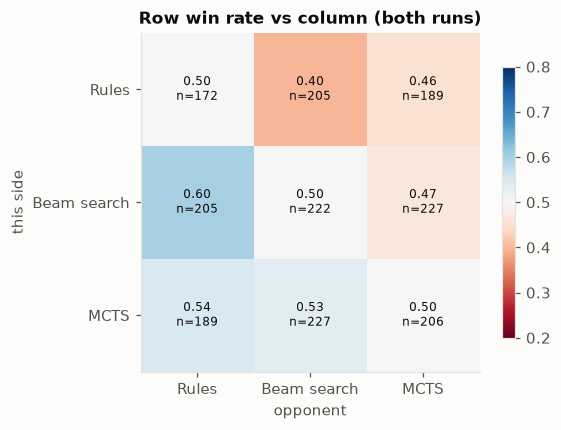

In [9]:
# matchup matrix: row = this side's search, col = opponent search, value = row's win rate
dec = sides[sides.won.notna()]
mat = dec.pivot_table(index="search", columns="opp_search", values="won", aggfunc="mean").reindex(
    index=SEARCH_ORDER, columns=SEARCH_ORDER).astype(float)
n = dec.pivot_table(index="search", columns="opp_search", values="won", aggfunc="size").reindex(
    index=SEARCH_ORDER, columns=SEARCH_ORDER)

fig, ax = plt.subplots(figsize=(5.2, 4))
im = ax.imshow(mat, cmap="RdBu", vmin=0.2, vmax=0.8)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{mat.iat[i, j]:.2f}\nn={n.iat[i, j]}", ha="center", va="center", fontsize=8, color=INK)
ax.set_xticks(range(3), SEARCH_ORDER); ax.set_yticks(range(3), SEARCH_ORDER)
ax.set(xlabel="opponent", ylabel="this side", title="Row win rate vs column (both runs)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8);

In [10]:
# side / pair bias: are A and B, or pairs, systematically different?
display(winrate(sides, ["run", "side"]).round(3))
winrate(sides, ["run", "pair", "side"]).round(3).unstack("side")

win_rate    n     se
run             side                      
20261105-002113 A         0.51  484  0.023
                B         0.49  484  0.023
20261105-075355 A        0.485  437  0.024
                B        0.515  437  0.024

win_rate           n          se       
side                        A      B    A    B      A      B
run             pair                                        
20261105-002113 0       0.525  0.475  238  238  0.032  0.032
                1       0.496  0.504  246  246  0.032  0.032
20261105-075355 0       0.494  0.506  156  156   0.04   0.04
                1       0.512  0.488  125  125  0.045  0.045
                2       0.455  0.545  156  156   0.04   0.04

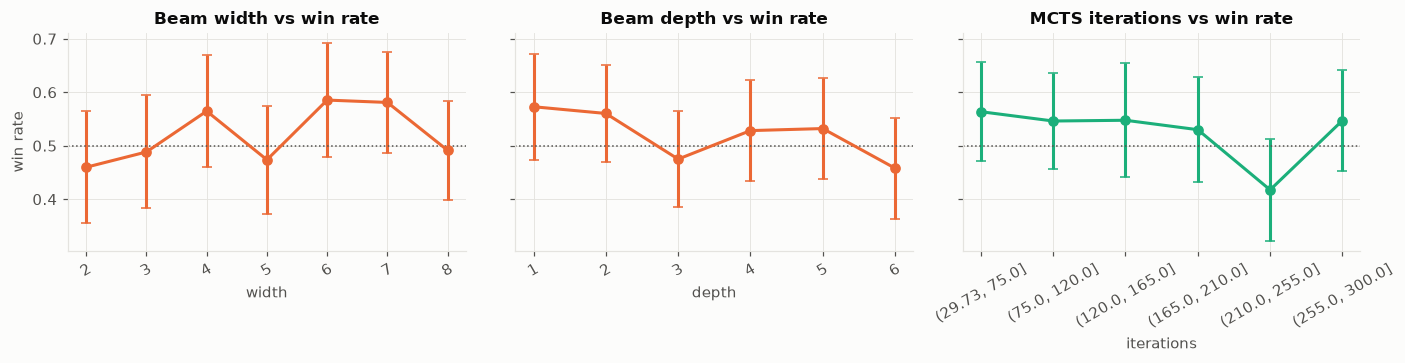

In [11]:
# config knobs vs win rate, within search type
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
beam = dec[dec.search == "Beam search"]
mcts = dec[dec.search == "MCTS"]
for ax, df, col, title, color in [
    (axes[0], beam, "width", "Beam width", SEARCH_COLORS["Beam search"]),
    (axes[1], beam, "depth", "Beam depth", SEARCH_COLORS["Beam search"]),
    (axes[2], mcts, "iterations", "MCTS iterations", SEARCH_COLORS["MCTS"]),
]:
    key = pd.cut(df[col], 6) if col == "iterations" else df[col]
    g = df.groupby(key, observed=True).won.agg(["mean", "size"])
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    xs = [str(i) for i in g.index]
    ax.errorbar(xs, g["mean"], yerr=1.96 * se, marker="o", markersize=6, color=color, capsize=3, linewidth=2)
    ax.axhline(0.5, color=INK2, linewidth=1, linestyle=":")
    ax.set(title=f"{title} vs win rate", xlabel=col)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("win rate");
plt.tight_layout()

In [12]:
# evaluation weights: correlation of each weight with winning, per search type
wcols = [f"w_{k}" for k in sd.WEIGHT_KEYS]
corr = pd.DataFrame({s: dec[dec.search == s][wcols].corrwith(dec[dec.search == s].won.astype(float))
                     for s in SEARCH_ORDER})
corr.round(3)

,Rules,Beam search,MCTS
w_fallDamage,-0.008,0.038,0.106
w_windCharge,0.045,0.087,0.032
w_pearl,0.075,-0.060,-0.028
w_height,0.041,0.028,-0.019
w_distance,-0.002,0.051,-0.018


## 4. Combat stats per side

In [13]:
stat_cols = ["dealt", "taken", "fall", "hits", "traded", "blocked", "windChargesUsed",
             "pearlsUsed", "applesEaten", "totemsPopped", "endHealth"]
sides.groupby(["search", "won"])[stat_cols].mean().round(2)

dealt   taken    fall  hits  traded  blocked  windChargesUsed  pearlsUsed  applesEaten  totemsPopped  endHealth
search      won                                                                                                                    
Beam search False   47.35  227.93   86.38  1.65    0.30      0.0            13.30        8.17         2.56           0.0      19.98
            True   138.72  130.03   80.94  3.52    0.36      0.0            13.71        8.18         2.29           0.0      18.53
MCTS        False   42.04  194.38   74.15  1.63    0.32      0.0            11.91        6.87         1.32           0.0      19.97
            True   154.82  111.46   73.37  3.86    0.33      0.0            13.31        7.80         1.24           0.0      18.43
Rules       False   72.03  307.27  134.84  3.39    0.62      0.0            22.33       11.82         2.10           0.0      19.72
            True   141.31  191.71  110.44  4.48    0.59      0.0            19.75       10.97         1.93           0.0      17.38

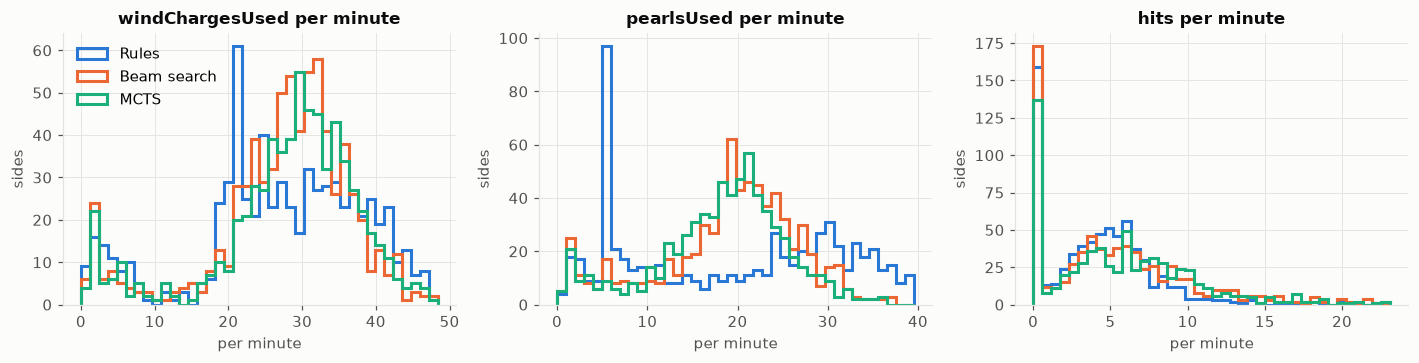

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
per_min = sides.assign(minutes=sides.seconds / 60)
for ax, col in zip(axes, ["windChargesUsed", "pearlsUsed", "hits"]):
    for s in SEARCH_ORDER:
        v = (per_min[per_min.search == s][col] / per_min[per_min.search == s].minutes).clip(upper=None)
        ax.hist(v, bins=40, histtype="step", linewidth=2, color=SEARCH_COLORS[s], label=s,
                range=(0, np.nanpercentile(per_min[col] / per_min.minutes, 99)))
    ax.set(title=f"{col} per minute", xlabel="per minute", ylabel="sides")
axes[0].legend()
plt.tight_layout()

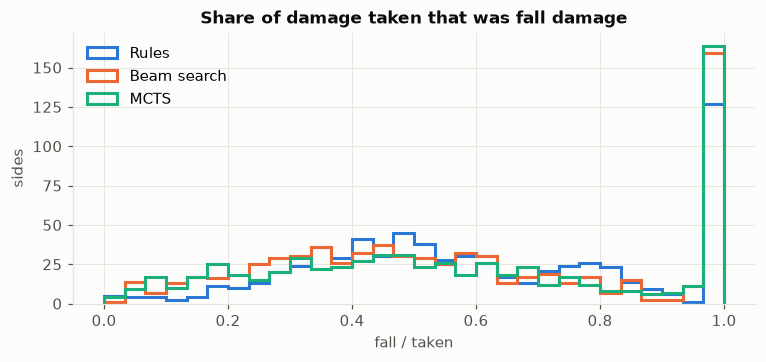

In [15]:
# fall damage is the main damage source? share of taken damage that was fall damage
s2 = sides[sides.taken > 0].assign(fall_share=lambda x: (x.fall / x.taken).clip(0, 1))
fig, ax = plt.subplots(figsize=(8, 3.2))
for s in SEARCH_ORDER:
    ax.hist(s2[s2.search == s].fall_share, bins=30, histtype="step", linewidth=2, color=SEARCH_COLORS[s], label=s)
ax.set(title="Share of damage taken that was fall damage", xlabel="fall / taken", ylabel="sides")
ax.legend();

## 5. Decisions: what the planner picks

In [16]:
dj = sd.attach_episode_info(decisions, sides)
print(f"{dj.label.isna().sum()} decisions belong to episodes with no episodes.jsonl row "
      "(the episode still running when the run was stopped)")
dj = dj[dj.label.notna()]

mix = pd.crosstab(dj.search, dj.acted_type, normalize="index").reindex(SEARCH_ORDER) * 100
order = mix.mean().sort_values(ascending=False).index
mix[order].round(1)

166 decisions belong to episodes with no episodes.jsonl row (the episode still running when the run was stopped)


acted_type,SpearLunge,Hold,Drift,EscapeLunge,PearlCatch,WindChargeJump,Eat,MaceStrike,Cushion,Escape
search,,,,,,,,,,
Rules,38.1,20.2,1.5,12.5,7.0,6.1,9.1,4.9,0.3,0.3
Beam search,16.9,22.5,19.9,8.7,10.1,7.2,5.6,5.3,3.6,0.1
MCTS,17.8,19.6,16.1,9.2,10.4,7.8,6.0,6.4,6.6,0.1


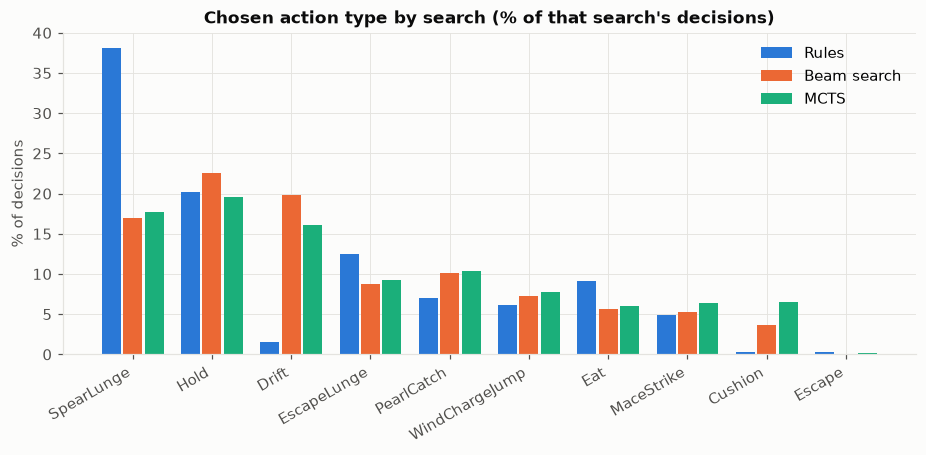

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.8))
mix_t = mix[order].T
x = np.arange(len(order)); w = 0.27
for i, s in enumerate(SEARCH_ORDER):
    ax.bar(x + (i - 1) * w, mix_t[s], w - 0.03, color=SEARCH_COLORS[s], label=s)
ax.set_xticks(x, order, rotation=30, ha="right")
ax.set(title="Chosen action type by search (% of that search's decisions)", ylabel="% of decisions")
ax.legend();

In [18]:
# does the action mix of winners differ from losers?
wl = pd.crosstab([dj.search, dj.won], dj.acted_type, normalize="index") * 100
(wl.xs(True, level="won") - wl.xs(False, level="won")).reindex(SEARCH_ORDER)[order].round(1)

acted_type,SpearLunge,Hold,Drift,EscapeLunge,PearlCatch,WindChargeJump,Eat,MaceStrike,Cushion,Escape
search,,,,,,,,,,
Rules,0.2,1.2,-0.1,-0.7,0.2,-0.7,-0.9,0.8,0.0,0.0
Beam search,3.1,-4.8,1.1,1.2,-1.4,-0.1,-0.7,1.9,-0.3,-0.0
MCTS,1.1,-3.0,2.6,1.6,-1.4,-0.8,-0.8,2.0,-1.2,-0.0


In [19]:
# replan triggers
trig = dj.triggers.str.split("|").explode()
trig = trig[trig != ""]
display(trig.value_counts().to_frame("decisions"))
print(f"{(dj.triggers == '').mean():.1%} of decisions had no trigger (first decision / plan exhausted)")

,decisions
triggers,
TARGET_DIVERGED,78087
LAUNCHED,25078
APEX,22064
LANDED,17901
DIVERGED,1916
TELEPORTED,1099
TARGET_CHANGED,243


30.8% of decisions had no trigger (first decision / plan exhausted)


### Planning latency and the expert labels

acted_ms                                              expert_ms                                                
                count  mean   std  min    50%    90%    99%    max     count   mean    std  min    50%    90%    99%     max
search                                                                                                                      
Beam search   41173.0  53.8  59.5  0.1   25.5  138.6  220.3  607.2   35804.0  164.9  155.7  0.1  118.5  391.6  579.4  1804.3
MCTS          31478.0  93.4  30.6  0.1  103.1  113.2  127.6  298.6   26118.0  196.3  159.0  0.1  178.0  417.7  600.5  1998.7
Rules        113906.0   2.4   5.4  0.0    0.2    9.8   23.5   61.9  107410.0  104.0  126.7  0.1   46.9  304.7  515.6   921.3

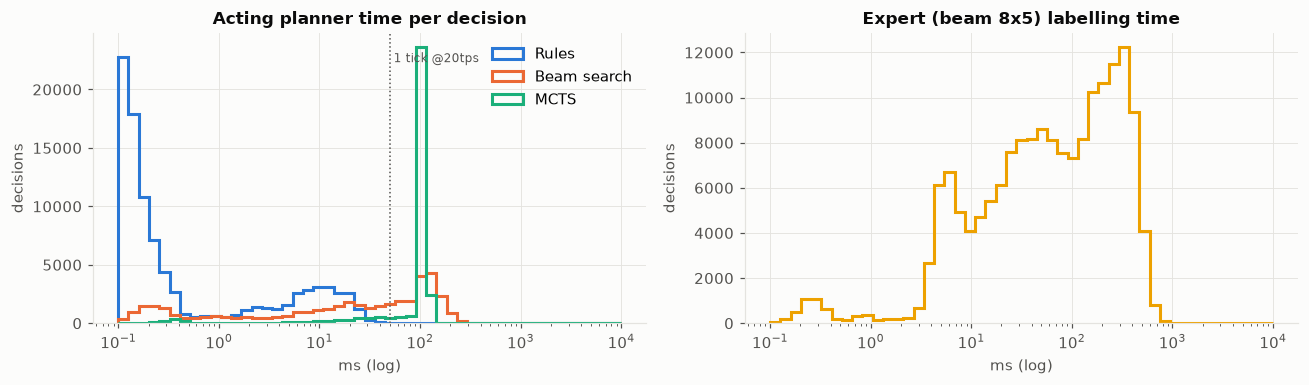

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.logspace(-1, 4, 50)
for s in SEARCH_ORDER:
    axes[0].hist(dj[dj.search == s].acted_ms.dropna(), bins=bins, histtype="step", linewidth=2,
                 color=SEARCH_COLORS[s], label=s)
axes[0].set_xscale("log")
axes[0].axvline(50, color=INK2, linestyle=":", linewidth=1)
axes[0].text(50, axes[0].get_ylim()[1] * 0.9, " 1 tick @20tps", fontsize=8, color=INK2)
axes[0].set(title="Acting planner time per decision", xlabel="ms (log)", ylabel="decisions")
axes[0].legend()

axes[1].hist(dj.expert_ms.dropna(), bins=bins, histtype="step", linewidth=2, color=SLOTS[3])
axes[1].set_xscale("log")
axes[1].set(title="Expert (beam 8x5) labelling time", xlabel="ms (log)", ylabel="decisions")
plt.tight_layout()

dj.groupby("search")[["acted_ms", "expert_ms"]].describe(percentiles=[.5, .9, .99]).round(1)

In [21]:
# how often does the acting agent agree with the expert, by search and action type
e = dj[dj.has_expert & ~dj.acted_explored.fillna(False)]
print(f"expert coverage: {dj.has_expert.mean():.1%} of decisions")
display(e.groupby("search").expert_agrees.mean().reindex(SEARCH_ORDER).to_frame("agreement").round(3))
pd.crosstab(e.acted_type, e.expert_type, normalize="index").round(2)

expert coverage: 90.8% of decisions


,agreement
search,
Rules,0.424031
Beam search,0.657063
MCTS,0.658536


expert_type,Cushion,Drift,Eat,Escape,EscapeLunge,Hold,MaceStrike,PearlCatch,SpearLunge,WindChargeJump
acted_type,,,,,,,,,,
Cushion,0.70,0.07,0.00,0.00,0.03,0.03,0.00,0.02,0.14,0.00
Drift,0.02,0.63,0.02,0.00,0.07,0.09,0.00,0.01,0.15,0.00
Eat,0.00,0.06,0.20,0.00,0.02,0.06,0.00,0.04,0.27,0.34
Escape,0.00,0.00,0.07,0.26,0.42,0.12,0.00,0.03,0.00,0.11
EscapeLunge,0.07,0.37,0.06,0.00,0.41,0.07,0.01,0.00,0.00,0.00
Hold,0.00,0.17,0.05,0.00,0.12,0.58,0.00,0.00,0.03,0.05
MaceStrike,0.04,0.17,0.01,0.00,0.03,0.03,0.70,0.01,0.00,0.00
PearlCatch,0.11,0.06,0.01,0.00,0.01,0.06,0.00,0.47,0.21,0.07
SpearLunge,0.03,0.14,0.04,0.00,0.00,0.09,0.00,0.01,0.56,0.14


In [22]:
# per-stop bookkeeping: labelled vs skipped expert calls
st = stops.groupby("run")[["replans", "expertLabeled", "expertSkipped"]].sum()
st["skipped %"] = 100 * st.expertSkipped / (st.expertLabeled + st.expertSkipped)
display(st.round(1))
stops.reason.value_counts()

,replans,expertLabeled,expertSkipped,skipped %
run,,,,
20261105-002113,227439,84196,8837,9.5
20261105-075355,232511,85265,8425,9.0


reason
killed               1474
died                  338
timeout               272
stopped by Server       4
Name: count, dtype: int64

### Exploration

In [23]:
display(dj.groupby("search").acted_explored.mean().reindex(SEARCH_ORDER).to_frame("explored").round(3))
# value gap between explored pick and what the agent would have picked
c_acted = candidates[candidates.is_acted]
c_best = candidates.loc[candidates.groupby(["run", "side", "key"]).acted_rank.idxmax().dropna()]
gap = (c_acted.set_index(["run", "side", "key"]).acted_rank
       - c_best.set_index(["run", "side", "key"]).acted_rank).rename("rank_gap")
gap = dj.set_index(["run", "side", "key"]).join(gap)
gap.groupby("acted_explored").rank_gap.describe().round(2)

,explored
search,
Rules,0.100
Beam search,0.099
MCTS,0.100


,count,mean,std,min,25%,50%,75%,max
acted_explored,,,,,,,,
False,167910.0,-1.23,5.34,-259.14,0.00,0.0,0.0,0.0
True,18644.0,-5.90,16.53,-288.93,-3.36,0.0,0.0,0.0


## 6. Candidate sets

In [24]:
display(dj.groupby("search").n_candidates.describe().round(2))
cand_types = candidates.type.value_counts()
offered = candidates.groupby(["run", "side", "key"]).type.agg(set)
print("how often each action type is on offer at a decision:")
pd.Series({t: offered.map(lambda s, t=t: t in s).mean() for t in cand_types.index}).sort_values(ascending=False).round(3)

,count,mean,std,min,25%,50%,75%,max
search,,,,,,,,
Beam search,41173.0,5.15,2.33,1.0,3.0,4.0,7.0,10.0
MCTS,31478.0,5.51,2.28,1.0,4.0,5.0,8.0,10.0
Rules,113906.0,4.84,2.07,1.0,4.0,4.0,7.0,10.0


how often each action type is on offer at a decision:


Hold              1.000
Drift             0.663
SpearLunge        0.531
Eat               0.527
EscapeLunge       0.344
WindChargeJump    0.318
PearlCatch        0.235
MaceStrike        0.193
Cushion           0.166
Escape            0.004
dtype: float64

In [25]:
# predicted outcomes from the simulator for every candidate
candidates.groupby("type")[["ticks", "dealt", "taken", "chance"]].agg(["mean", "median"]).round(2)

ticks        dealt        taken        chance       
                 mean median  mean median  mean median   mean median
type                                                                
Cushion         14.06   14.0  0.03    0.0  0.00    0.0   1.00   1.00
Drift            7.80   10.0  0.07    0.0  1.35    0.0   1.00   1.00
Eat             17.12   14.0  0.04    0.0  3.48    0.0   1.00   1.00
Escape           4.71    4.0  0.00    0.0  0.00    0.0   1.00   1.00
EscapeLunge      6.92    8.0  0.15    0.0  0.87    0.0   1.00   1.00
Hold             9.91   10.0  0.04    0.0  0.72    0.0   1.00   1.00
MaceStrike      12.72   11.0  6.70    0.0  0.55    0.0   1.00   1.00
PearlCatch      12.99   14.0  0.01    0.0  1.34    0.0   0.86   0.87
SpearLunge       6.81    8.0  0.00    0.0  0.56    0.0   1.00   1.00
WindChargeJump   7.51    4.0  0.00    0.0  0.03    0.0   1.00   1.00

## 7. Actions: did they work?

In [26]:
status = pd.crosstab(actions.type, actions.status, normalize="index") * 100
status["n"] = actions.type.value_counts()
status.sort_values("n", ascending=False).round(1)

status,DONE,FAILED,INTERRUPTED,n
type,,,,
Hold,64.3,0.0,35.7,88776
SpearLunge,44.3,0.0,55.7,58694
EscapeLunge,38.7,0.0,61.3,21465
PearlCatch,87.0,13.0,0.0,18653
Drift,36.5,3.4,60.2,17277
Eat,9.9,0.2,89.9,15596
MaceStrike,34.3,33.5,32.1,14752
WindChargeJump,4.5,5.1,90.4,13018
Cushion,58.8,0.7,40.5,4607


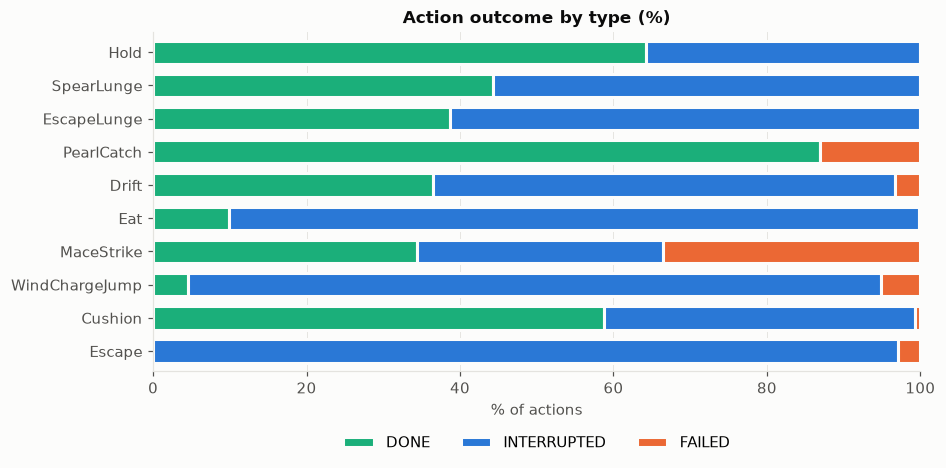

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
st = status.sort_values("n")[["DONE", "INTERRUPTED", "FAILED"]].fillna(0)
st.plot.barh(stacked=True, ax=ax, color=[SLOTS[2], SLOTS[0], SLOTS[1]], width=0.7, edgecolor="#fcfcfb", linewidth=2)
ax.set(title="Action outcome by type (%)", xlabel="% of actions", ylabel="")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15));

In [28]:
# top failure reasons per action type
f = actions[actions.status == "FAILED"]
f.groupby(["type", "reason"]).size().rename("n").reset_index().sort_values("n", ascending=False).head(20)

,type,reason,n
11,MaceStrike,landed before the hit,2749
3104,WindChargeJump,no explosion,660
2181,PearlCatch,no catch,563
5,Drift,on the ground,554
2187,PearlCatch,pearl disappeared without a teleport,471
2185,PearlCatch,no wind charge aim catches the pearl from here...,222
2182,PearlCatch,no ender pearl ready,78
2169,MaceStrike,target is dead,41
2189,PearlCatch,teleported before the wind charge was thrown,34
2177,PearlCatch,delay 1 is out of range (p=0.50),29


In [29]:
# interruptions: which replan trigger cut each action short
i = actions[actions.status == "INTERRUPTED"]
pd.crosstab(i.type, i.reason).T.assign(total=lambda x: x.sum(axis=1)).sort_values("total", ascending=False).head(10)

type,Cushion,Drift,Eat,Escape,EscapeLunge,Hold,MaceStrike,SpearLunge,WindChargeJump,total
reason,,,,,,,,,,
[TARGET_DIVERGED],1824,7042,9083,35,7660,18078,2971,21224,2460,70377
[APEX],14,2818,2453,36,604,8373,1036,3294,563,19191
[LAUNCHED],10,189,328,90,220,2521,633,542,7467,12000
"[LANDED, LAUNCHED]",0,0,997,6,2879,654,0,3456,75,8067
[LANDED],0,0,521,4,1330,515,0,2228,125,4723
"[APEX, TARGET_DIVERGED]",1,222,203,1,74,558,43,462,53,1617
"[LAUNCHED, TARGET_DIVERGED]",1,10,19,5,13,124,13,63,832,1080
[DIVERGED],2,43,123,174,37,211,10,363,52,1015
"[LANDED, LAUNCHED, TARGET_DIVERGED]",0,0,66,0,174,36,0,429,4,709


### Calibration of the simulator's success chance

Join each decision to the action it started (same name, `startTick == clientTick`) and compare the
simulator's predicted `chance` for the chosen action with how often that action finished `DONE`
(interrupted actions are excluded; they neither succeeded nor failed).

Only `PearlCatch` gets a graded chance; every other action is predicted at `chance = 1.0`, so for
those the table's `realised` column is simply their non-interrupted success rate.

decisions matched to an action_end: 99.3%


,pred,realised,n
acted_type,,,
Cushion,1.000,0.998,2004
Drift,1.000,0.996,5003
Eat,1.000,0.976,1125
Escape,1.000,0.000,11
EscapeLunge,1.000,1.000,7694
Hold,1.000,1.000,7921
MaceStrike,1.000,0.802,4733
PearlCatch,0.807,0.876,15082
SpearLunge,1.000,1.000,23748


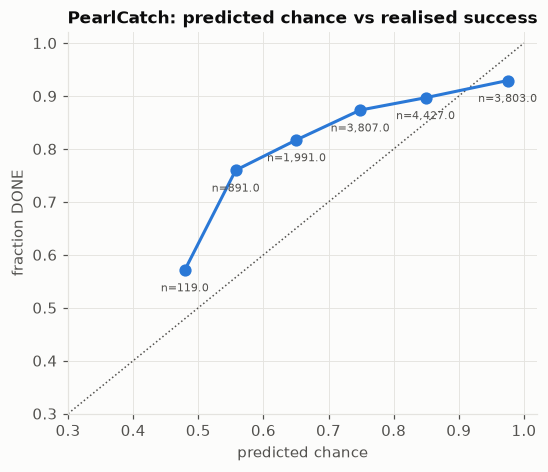

In [30]:
da = sd.attach_action_outcome(dj, actions)
print(f"decisions matched to an action_end: {da.action_status.notna().mean():.1%}")
cal = da[da.action_status.isin(["DONE", "FAILED"]) & da.acted_out_chance.notna()].copy()
cal["ok"] = cal.action_status == "DONE"
cal["bin"] = pd.cut(cal.acted_out_chance, np.linspace(0, 1, 11), include_lowest=True)

g = cal[cal.acted_type == "PearlCatch"].groupby("bin", observed=True).agg(
    p=("acted_out_chance", "mean"), ok=("ok", "mean"), n=("ok", "size"))
g = g[g.n >= 20]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":")
ax.plot(g.p, g.ok, marker="o", markersize=7, color=SLOTS[0])
for _, row in g.iterrows():
    ax.annotate(f"n={row.n:,}", (row.p, row.ok), textcoords="offset points", xytext=(0, -14),
                ha="center", fontsize=7, color=INK2)
ax.set(title="PearlCatch: predicted chance vs realised success", xlabel="predicted chance",
       ylabel="fraction DONE", xlim=(0.3, 1.02), ylim=(0.3, 1.02))

cal.groupby("acted_type").agg(pred=("acted_out_chance", "mean"), realised=("ok", "mean"), n=("ok", "size")).round(3)

In [31]:
# payload checks: spear-lunge and mace-strike impulse prediction error
def payloads(ptype):
    p = actions[actions.payloadType == ptype].payload.map(orjson.loads)
    return pd.json_normalize(p.tolist()).set_index(p.index)

lunge = payloads("Lunged")
err = np.linalg.norm(np.stack(lunge.expected) - np.stack(lunge.measured), axis=1)
strike = payloads("Struck")
s_err = (strike.measuredLaunch - strike.expectedLaunch).abs()
catch = payloads("Caught")
c_err = np.linalg.norm(np.stack(catch.teleportedTo) - np.stack(catch["plan.destination"]), axis=1)

pd.DataFrame({
    "lunge |expected-measured| (b/t)": pd.Series(err).describe(percentiles=[.5, .9, .99]),
    "strike launch error": s_err.describe(percentiles=[.5, .9, .99]),
    "pearl teleport vs planned dest (blocks)": pd.Series(c_err).describe(percentiles=[.5, .9, .99]),
}).round(4)

,lunge |expected-measured| (b/t),strike launch error,pearl teleport vs planned dest (blocks)
count,34311.0000,5066.0000,16224.0000
mean,0.0107,0.0061,2.0128
std,0.0391,0.0667,8.2188
min,0.0000,0.0000,0.0001
50%,0.0001,0.0000,0.2816
90%,0.0346,0.0000,3.4395
99%,0.1711,0.0786,21.9880
max,1.3811,1.2839,181.1077


option.damage                                           option.fall                                      
                   count  mean   std  min   25%   50%   75%    max       count  mean  std  min  25%  50%   75%   max
option.pre                                                                                                          
AXE                395.0  31.4  16.3  9.2  18.8  23.7  39.4   81.0       395.0  11.4  9.2  1.8  4.8  6.6  18.8  56.9
HAND               867.0  28.4  14.7  7.3  16.3  21.9  40.3   83.3       867.0  10.3  8.8  1.6  2.7  5.4  17.3  42.3
SPEAR             3348.0  30.1  14.8  7.5  18.8  27.1  38.8  132.0      3348.0  10.5  8.5  1.6  4.5  5.5  17.3  69.0
SWORD              456.0  35.4  17.6  9.4  21.5  35.4  46.6   75.8       456.0  12.5  8.4  1.7  5.0  9.7  20.1  39.8

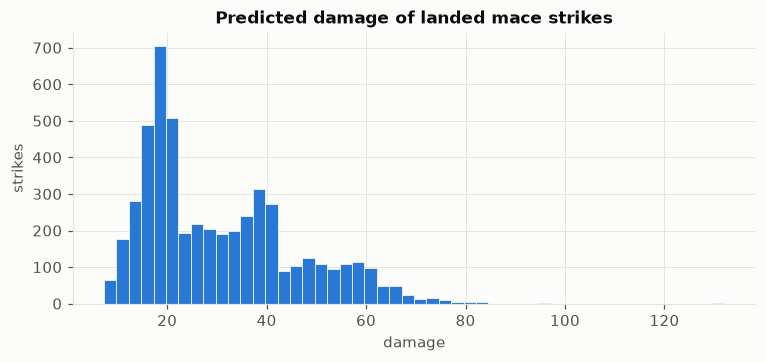

In [32]:
# mace strikes: pre-hit weapon, crit, damage
display(strike.groupby("option.pre")[["option.damage", "option.fall"]].describe().round(1))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(strike["option.damage"], bins=50, color=SLOTS[0], edgecolor="#fcfcfb", linewidth=0.5)
ax.set(title="Predicted damage of landed mace strikes", xlabel="damage", ylabel="strikes");

## 8. Spatial and state features at decision time

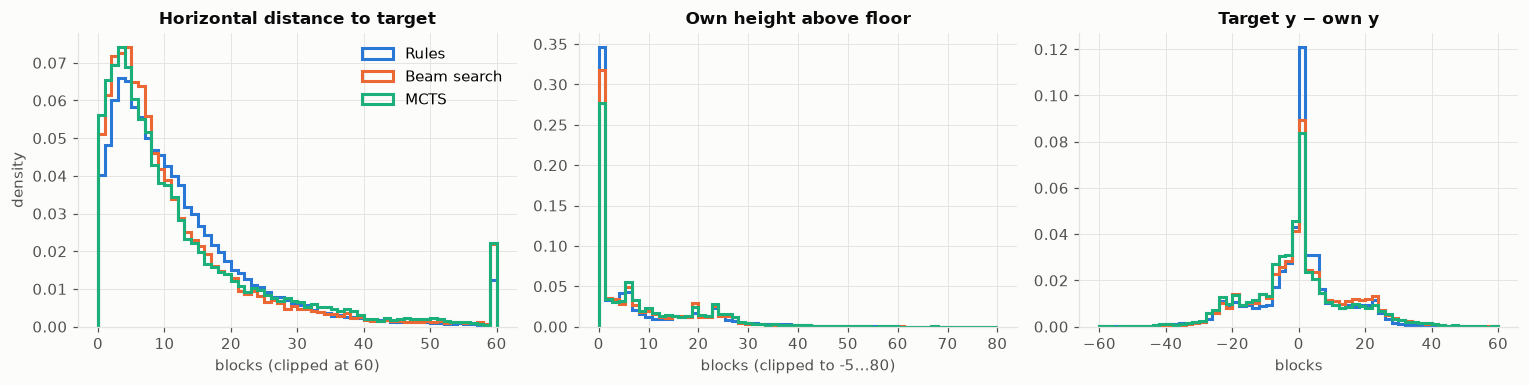

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ground = -60
for s in SEARCH_ORDER:
    x = dj[dj.search == s]
    kw = dict(histtype="step", linewidth=2, color=SEARCH_COLORS[s], label=s, density=True)
    axes[0].hist(x.hdist.clip(upper=60), bins=60, **kw)
    axes[1].hist((x.self_pos_y - ground).clip(-5, 80), bins=60, **kw)
    axes[2].hist(x.dy.clip(-60, 60), bins=60, **kw)
axes[0].set(title="Horizontal distance to target", xlabel="blocks (clipped at 60)", ylabel="density")
axes[1].set(title="Own height above floor", xlabel="blocks (clipped to -5…80)")
axes[2].set(title="Target y − own y", xlabel="blocks")
axes[0].legend()
plt.tight_layout()

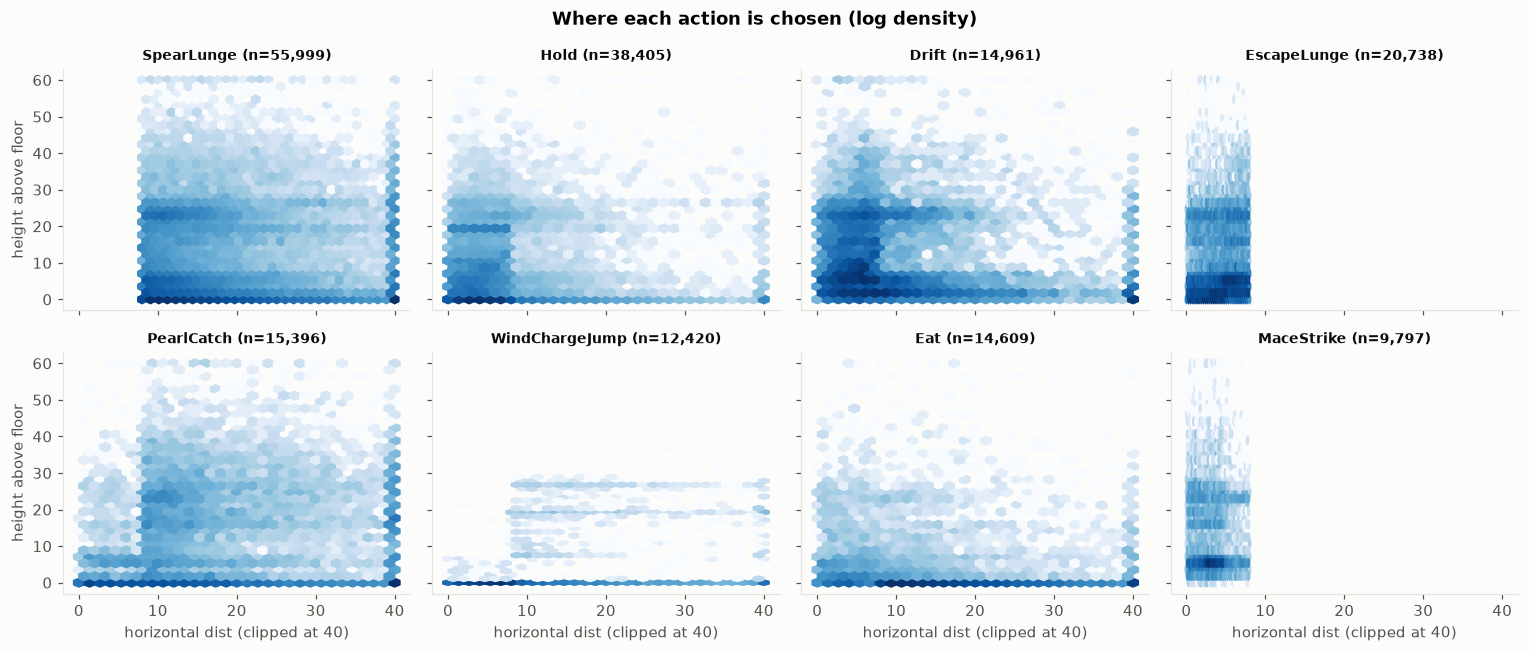

In [34]:
# where does each action get chosen? height vs horizontal distance
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for ax, t in zip(axes.flat, order[:8]):
    x = dj[dj.acted_type == t]
    ax.hexbin(x.hdist.clip(upper=40), (x.self_pos_y - ground).clip(-2, 60), gridsize=30, cmap="Blues",
              bins="log", mincnt=1)
    ax.set_title(f"{t} (n={len(x):,})", fontsize=9)
    ax.grid(False)
for ax in axes[1]: ax.set_xlabel("horizontal dist (clipped at 40)")
for ax in axes[:, 0]: ax.set_ylabel("height above floor")
fig.suptitle("Where each action is chosen (log density)", fontweight="bold")
plt.tight_layout()

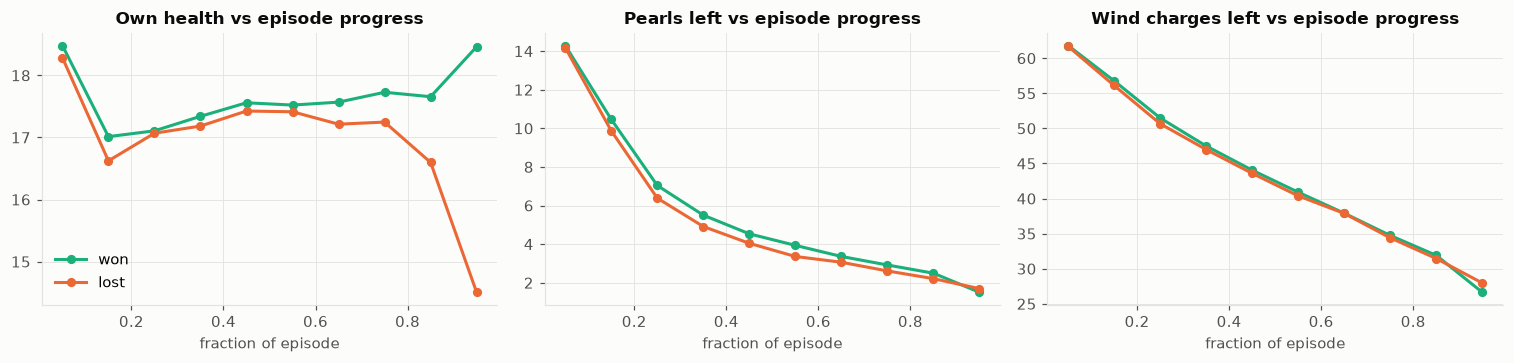

In [35]:
# resources and health over an episode (normalised time)
dj["t_frac"] = dj.clientTick / dj.ep_ticks.replace(0, np.nan)
dj["t_bin"] = pd.cut(dj.t_frac.clip(0, 1), np.linspace(0, 1, 11), include_lowest=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, col, title in [(axes[0], "self_health", "Own health"), (axes[1], "kit_ender_pearl", "Pearls left"),
                       (axes[2], "kit_wind_charge", "Wind charges left")]:
    for won, c, lab in [(True, SLOTS[2], "won"), (False, SLOTS[1], "lost")]:
        g = dj[dj.won == won].groupby("t_bin", observed=True)[col].mean()
        ax.plot(np.linspace(0.05, 0.95, len(g)), g.values, marker="o", markersize=5, color=c, label=lab)
    ax.set(title=f"{title} vs episode progress", xlabel="fraction of episode")
axes[0].legend()
plt.tight_layout()

## 9. Run-to-run comparison

In [36]:
cmp = pd.DataFrame({
    "median episode ticks": episodes.groupby("run").ticks.median(),
    "timeouts %": episodes.groupby("run").reason.apply(lambda r: 100 * (r == "timeout").mean()),
    "decisions / episode-side": decisions.groupby("run").size() / sides.groupby("run").size(),
    "decisions / 100 ticks": decisions.groupby("run").size() / episodes.groupby("run").ticks.sum() / 2 * 100,
    "mean acting ms": decisions.groupby("run").acted_ms.mean(),
    "explore %": 100 * decisions.groupby("run").acted_explored.mean(),
    "expert coverage %": 100 * decisions.groupby("run").has_expert.mean(),
    "action FAILED %": 100 * actions.groupby("run").status.apply(lambda s: (s == "FAILED").mean()),
    "mean mspt": episodes.groupby("run").msptMean.mean(),
}).T
cmp.round(2)

run,20261105-002113,20261105-075355
median episode ticks,455.00,478.50
timeouts %,11.99,14.20
decisions / episode-side,85.82,93.69
decisions / 100 ticks,8.84,8.83
mean acting ms,29.48,28.75
explore %,9.98,10.01
expert coverage %,90.50,91.01
action FAILED %,3.53,3.34
mean mspt,1.00,1.61


In [37]:
pd.crosstab(decisions.acted_type, decisions.run, normalize="columns").mul(100).round(1).assign(
    delta=lambda x: x[RUN_NAMES[1]] - x[RUN_NAMES[0]]).sort_values("delta")

run,20261105-002113,20261105-075355,delta
acted_type,,,
Drift,8.5,7.6,-0.9
PearlCatch,8.6,7.9,-0.7
Hold,20.8,20.4,-0.4
Cushion,2.1,2.0,-0.1
MaceStrike,5.3,5.2,-0.1
Escape,0.2,0.2,0.0
WindChargeJump,6.6,6.7,0.1
EscapeLunge,11.0,11.2,0.2
Eat,7.7,8.0,0.3


## 10. Data quality notes

Checks to keep in mind when training on these logs.

In [38]:
checks = {
    "decisions without an episodes row": int(sd.attach_episode_info(decisions, sides).label.isna().sum()),
    "decisions with no expert label": int((~decisions.has_expert).sum()),
    "decisions not matched to an action_end": int(sd.attach_action_outcome(decisions, actions).action_status.isna().sum()),
    "episodes with no winner": int(episodes.winner.isna().sum()),
    "draws that are not timeouts": int((episodes.winner.isna() & (episodes.reason != "timeout")).sum()),
    "stops per (run,episode,side) != 1": int((stops.groupby(["run", "pair", "episode", "role"]).size() != 1).sum()),
}
pd.Series(checks).to_frame("count")

,count
decisions without an episodes row,166
decisions with no expert label,17262
decisions not matched to an action_end,1377
episodes with no winner,121
draws that are not timeouts,0
"stops per (run,episode,side) != 1",0
